# Backpropagation from Scratch and Optimizer Comparison

**Course:** Deep Learning (2087101)

This notebook covers both assessment questions:
1. Implement backpropagation for a one-hidden-layer MLP using NumPy, MSE loss, and standard gradient descent.
2. Train a feedforward neural network on synthetic data with SGD + momentum and Adam, then compare convergence and final loss.

Run all cells from top to bottom to generate real output logs and plots.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

## Question 1: Backpropagation from scratch

We use a small regression dataset with two input features and one output. The network has one hidden layer. Sigmoid activation is used in the hidden layer and output layer. The loss is Mean Squared Error (MSE). Gradients are calculated using the chain rule and weights are updated using standard gradient descent.

In [2]:
# Create a simple synthetic regression dataset
X = np.array([
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0],
    [0.2, 0.7],
    [0.8, 0.3]
], dtype=float)

y = np.array([[0.1], [0.6], [0.5], [0.9], [0.55], [0.6]], dtype=float)

def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

def sigmoid_derivative(a):
    return a * (1 - a)

input_size = X.shape[1]
hidden_size = 4
output_size = 1
learning_rate = 0.5
epochs = 5000

W1 = np.random.randn(input_size, hidden_size) * 0.5
b1 = np.zeros((1, hidden_size))
W2 = np.random.randn(hidden_size, output_size) * 0.5
b2 = np.zeros((1, output_size))

loss_history = []

for epoch in range(epochs):
    # Forward pass
    hidden = sigmoid(X @ W1 + b1)
    prediction = sigmoid(hidden @ W2 + b2)

    # MSE loss
    error = prediction - y
    loss = np.mean(error ** 2)
    loss_history.append(loss)

    # Backward pass: derivative of MSE with respect to output
    d_prediction = (2 / y.size) * error
    d_output_layer = d_prediction * sigmoid_derivative(prediction)

    dW2 = hidden.T @ d_output_layer
    db2 = np.sum(d_output_layer, axis=0, keepdims=True)

    d_hidden = (d_output_layer @ W2.T) * sigmoid_derivative(hidden)
    dW1 = X.T @ d_hidden
    db1 = np.sum(d_hidden, axis=0, keepdims=True)

    # Standard gradient descent update
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

if not np.all(np.isfinite(loss_history)):
    raise ValueError("Training produced a non-finite loss.")

print("Backpropagation from scratch")
print("Initial MSE:", round(loss_history[0], 6))
print("Final MSE:", round(loss_history[-1], 6))
print("Epochs:", epochs)
print("\nPredictions:")
for actual_input, target, pred in zip(X, y, sigmoid(sigmoid(X @ W1 + b1) @ W2 + b2)):
    print("Input:", actual_input, "Target:", target[0], "Prediction:", round(float(pred[0]), 4))

Backpropagation from scratch
Initial MSE: 0.072714
Final MSE: 0.000116
Epochs: 5000

Predictions:
Input: [0. 0.] Target: 0.1 Prediction: 0.1018
Input: [0. 1.] Target: 0.6 Prediction: 0.6164
Input: [1. 0.] Target: 0.5 Prediction: 0.5067
Input: [1. 1.] Target: 0.9 Prediction: 0.8952
Input: [0.2 0.7] Target: 0.55 Prediction: 0.5314
Input: [0.8 0.3] Target: 0.6 Prediction: 0.5973


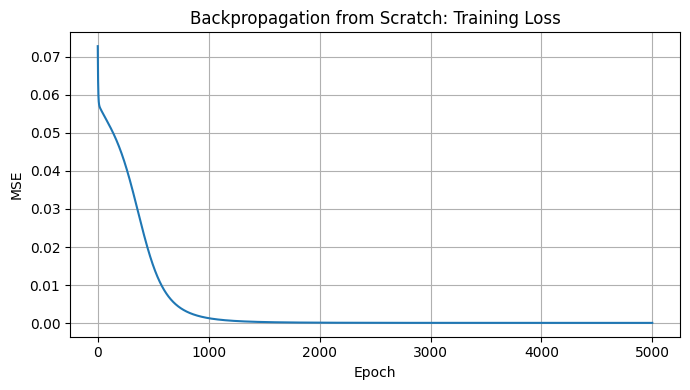

In [3]:
plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.title("Backpropagation from Scratch: Training Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.grid(True)
plt.tight_layout()
plt.show()

### Backpropagation steps

1. Perform a forward pass to calculate the hidden activations and prediction.
2. Calculate MSE between predictions and targets.
3. Calculate the output-layer gradient using the chain rule.
4. Propagate the error back to the hidden layer.
5. Calculate gradients for weights and biases.
6. Update each parameter by subtracting learning rate × gradient.

## Question 2: Compare SGD with momentum and Adam

A synthetic binary-classification dataset is generated with `make_moons`. Both models use the same network, data split, number of epochs, batch size, and loss function. Only the optimizer changes. The notebook records the average training loss for each epoch, test loss, and time taken.

In [4]:
# Install scikit-learn if needed in Colab:
# %pip install scikit-learn torch

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)
np.random.seed(42)

X2, y2 = make_moons(n_samples=2000, noise=0.20, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32)

train_loader = DataLoader(
    TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True
)

class FeedforwardNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.network(x)

def train_model(optimizer_name, epochs=100):
    # Reinitialize weights to make the comparison fair.
    torch.manual_seed(123)
    model = FeedforwardNet()
    criterion = nn.BCEWithLogitsLoss()

    if optimizer_name == "SGD + Momentum":
        optimizer = torch.optim.SGD(model.parameters(), lr=0.03, momentum=0.9)
    else:
        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

    history = []
    start = time.time()

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        total_items = 0

        for xb, yb in train_loader:
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * xb.size(0)
            total_items += xb.size(0)

        history.append(total_loss / total_items)

    elapsed = time.time() - start
    model.eval()
    with torch.no_grad():
        test_loss = criterion(model(X_test_t), y_test_t).item()
        predicted = (torch.sigmoid(model(X_test_t)) >= 0.5).float()
        accuracy = (predicted.eq(y_test_t).float().mean().item()) * 100

    return model, history, test_loss, accuracy, elapsed

sgd_model, sgd_history, sgd_test_loss, sgd_accuracy, sgd_time = train_model("SGD + Momentum")
adam_model, adam_history, adam_test_loss, adam_accuracy, adam_time = train_model("Adam")

print("Optimizer comparison (results from this run)")
print(f"SGD + Momentum | final train loss: {sgd_history[-1]:.6f} | test loss: {sgd_test_loss:.6f} | accuracy: {sgd_accuracy:.2f}% | time: {sgd_time:.2f}s")
print(f"Adam           | final train loss: {adam_history[-1]:.6f} | test loss: {adam_test_loss:.6f} | accuracy: {adam_accuracy:.2f}% | time: {adam_time:.2f}s")

Optimizer comparison (results from this run)
SGD + Momentum | final train loss: 0.065314 | test loss: 0.107641 | accuracy: 96.00% | time: 2.10s
Adam           | final train loss: 0.069131 | test loss: 0.094656 | accuracy: 95.00% | time: 2.53s


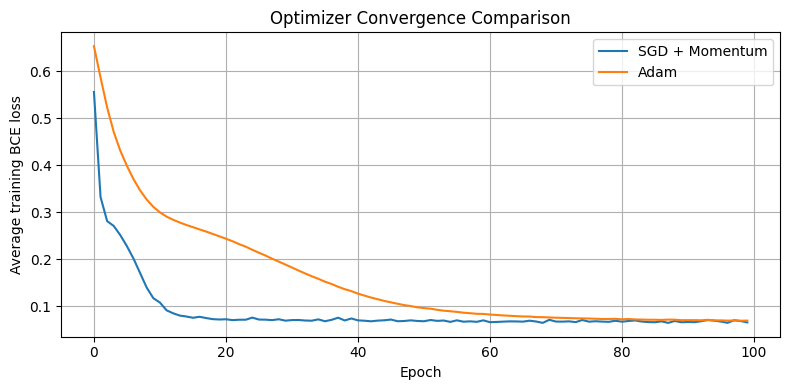

In [5]:
plt.figure(figsize=(8, 4))
plt.plot(sgd_history, label="SGD + Momentum")
plt.plot(adam_history, label="Adam")
plt.title("Optimizer Convergence Comparison")
plt.xlabel("Epoch")
plt.ylabel("Average training BCE loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [6]:
# Define convergence speed as the first epoch reaching 110% of the best final
# training loss achieved by either optimizer. This gives a reproducible comparison.
target_loss = 1.10 * min(sgd_history[-1], adam_history[-1])

def first_epoch_below(history, threshold):
    for index, value in enumerate(history, start=1):
        if value <= threshold:
            return index
    return None

print("Convergence threshold:", round(target_loss, 6))
print("SGD + Momentum first epoch below threshold:", first_epoch_below(sgd_history, target_loss))
print("Adam first epoch below threshold:", first_epoch_below(adam_history, target_loss))

Convergence threshold: 0.071846
SGD + Momentum first epoch below threshold: 20
Adam first epoch below threshold: 81


## Results and interpretation

Use the printed output from your own run. The convergence plot shows how quickly each optimizer reduces training loss. SGD with momentum accumulates a moving direction from past gradients and can reduce oscillations. Adam adapts the learning rate for each parameter using moving averages of gradients and squared gradients; it often converges quickly, but the winner depends on the dataset and hyperparameters.

Report both final training loss and test loss. Use elapsed training time as an additional practical measure. Do not claim one optimizer is always best: explain what your measured results show.

## Conclusion

Backpropagation calculates gradients by applying the chain rule from the output layer back to the hidden layer. Standard gradient descent updates weights using these gradients and a learning rate. In the second experiment, SGD with momentum and Adam are compared on the same synthetic dataset and network. Their loss curves, final losses, accuracies, and training times help show differences in convergence behavior.